# Codes that are not CSS: the three questions

> **In short.**
> * **The setting.** A *code* protects qubits by spreading them over more qubits. It is described by its *stabilizers*: products of Pauli operators ($X$ = bit flip, $Z$ = phase flip) that the protected state does not notice, so that measuring them reveals errors without disturbing the data. In the simplest codes (*CSS codes*) every stabilizer is all-$X$ or all-$Z$. Here the codes are not like that: their stabilizers mix $X$ and $Z$, like `XZZXI`.
> * **The question.** Does the tool still find the code, and what a block of gates does to the protected qubit, from the gates alone?
> * **The answer.** Yes. It finds the [[5,1,3]] code from a ring of CZ gates, builds its ideal encoder (checked with numpy) and writes it in the isometry AP normal form of Yeh et al., and finds that $H$ then $S$ on every qubit is the logical $SH$, while $H$ alone leaves the code. One case is not covered: a code that differs from run to run.
> * **How to read the pictures.** Lines are qubits, time runs left to right; green and red dots are Z- and X-spiders, and a blue line between two green dots is a CZ gate. Shades mark the blocks of a program.
> * New to codes and ZX-diagrams? Start with [TInjectionWalkthrough.ipynb](TInjectionWalkthrough.ipynb), Part A.

In a *CSS code* every stabilizer is made of `X`s only or of `Z`s only (the Steane code, the surface code). Many codes are not like that. The best known is the **[[5,1,3]] code**, the smallest code that corrects any error on one qubit: its stabilizers mix `X` and `Z`, for example `XZZXI`.

This notebook shows that the tool answers all three questions of the paper for such codes, from the gates alone:

1. **which code** the qubits are in: the stabilizers are read off the program, mixed ones included;
2. **what a block does** to the logical qubits: computed between *ideal encoders*. For a code that is not CSS, the tool builds the ideal encoder from its Choi state, following Yeh, Huang, Kissinger, Li and van de Wetering (*A three-way normal form for stabiliser codes*, in preparation);
3. whether it does so **in every run**.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')                      # for the test suite's Steane encoder
import numpy as np
import pyzx as zx
from pyzx.circuit import Circuit
from pyzx.circuit.gates import CNOT, CZ, HAD, S, Measurement, Reset
from zxqec.qprogram import QProgram, ParityControlled, check_detectors
from zxqec.codes import iap_normal_form, logical_action
from zxqec.spacetime import draw_graph, draw_program, draw_relaxed
from tests.programs import steane_encoder

CHECKS = ['XZZXI', 'IXZZX', 'XIXZZ', 'ZXIXZ']       # four of the code's checks

def five_qubit_program(gate=None, name=None):
    """Qubit 0 carries the input, qubits 1-5 hold the [[5,1,3]] code, qubit 6 measures the checks."""
    p = QProgram(7, bits=5, initial_states={**{q: '+' for q in range(1, 6)}, 6: '0'})
    c = Circuit(7, bit_amount=5)
    c.add_gate(HAD(0))
    for q in range(1, 6):
        c.add_gate(CZ(q, q % 5 + 1))                # a ring of CZ gates on qubits 1-5
    for q in range(1, 6):
        c.add_gate(CZ(0, q))                        # join the input to every qubit of the ring
    c.add_gate(HAD(0))
    c.add_gate(Measurement(0, result_symbol='c[0]'))    # and measure it in the X basis
    p.add_circuit(c, name='encode')
    c = Circuit(7, bit_amount=5)
    for k, check in enumerate(CHECKS):              # measure each check with the helper qubit
        c.add_gate(HAD(6))
        for j, letter in enumerate(check):
            if letter == 'X':
                c.add_gate(CNOT(6, 1 + j))
            if letter == 'Z':
                c.add_gate(CZ(6, 1 + j))
        c.add_gate(HAD(6))
        c.add_gate(Measurement(6, result_symbol='c[%d]' % (k + 1)))
        c.add_gate(Reset(6))
    p.add_circuit(c, name='measure the four checks')
    if gate is not None:                            # a gate on every qubit of the code
        c = Circuit(7, bit_amount=5)
        for q in range(1, 6):
            for g in gate:
                c.add_gate(g(q))
        p.add_circuit(c, name=name)
    return p

## 1. Which code?

The encoder is a ring of `CZ` gates with the input joined to every qubit and then measured. Nothing in the program says "[[5,1,3]]".

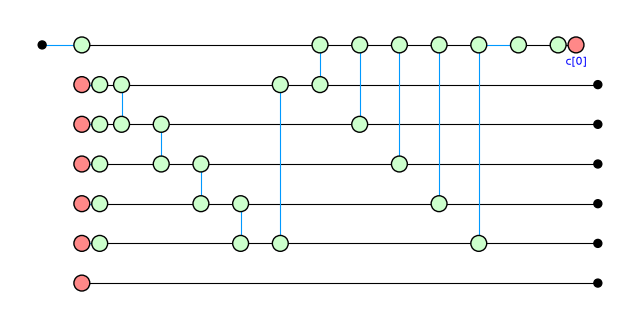

In [2]:
p = five_qubit_program()
draw_graph(p.stage_graph(0, classical=False), show_time=False, figsize=(8, 4))

The encoder stage as a ZX-diagram, time running left to right: qubit 0 (top) carries the input (its wire starts with a Hadamard, the blue segment), qubits 1-5 start in $|+\rangle$; the blue lines between them are the ring of CZ gates, then the CZ gates from qubit 0 to each of them, and qubit 0 is measured at the end (`c[0]`). Qubit 6, the helper for the checks, is idle here.

And the code the tool reads off the program after this stage:

In [3]:
print(p.code_at(0))

[[5, 1, 3]] stabilizer code on qubits 1, 2, 3, 4, 5
    stabilizer +XZZXI
    stabilizer +ZZXIX
    stabilizer +ZXIXZ
    stabilizer +IXZZX
    logical X XXXXX   logical Z ZZZZZ
fixed qubits: 6 in |0>


The tool finds a **[[5,1,3]] stabilizer code** (not "CSS code") on qubits 1-5. Its generators mix `X` and `Z`: they are four of the five cyclic shifts of `XZZXI`, which generate the code's stabilizer group. The logical operators are `XXXXX` and `ZZZZZ`. The helper qubit 6 is left in `|0>`.

## 2. The ideal encoder

The logical action of a block is computed between *ideal encoders*: the map `E` from the logical qubit to the code with `E X = Xbar E`, `E Z = Zbar E`, whose image is the code space. For CSS codes the tool draws `E` as a two-layer diagram; that form cannot give a code that is not CSS, so here `code.encoder()` builds `E` from its Choi state instead. We check the three properties with numpy:

In [4]:
code = p.code_at(0).data()                         # the code on qubits 1-5, without the helper qubit
E = code.encoder().to_matrix()
E = E / np.linalg.norm(E[:, 0])                     # the diagram is built up to a scalar

PAULI = {'I': np.eye(2), 'X': np.array([[0, 1], [1, 0]]), 'Y': np.array([[0, -1j], [1j, 0]]),
         'Z': np.diag([1, -1])}
def matrix(p):
    m = np.array([[1]])
    for letter in p.letters:
        m = np.kron(m, PAULI[letter])
    return (-1) ** int(p.sign) * m

print("every stabilizer fixes E:    ", max(np.abs(matrix(g) @ E - E).max() for g in code.stabilizers))
print("Xbar E = E X:                ", np.abs(matrix(code.logical_x[0]) @ E - E @ PAULI['X']).max())
print("Zbar E = E Z:                ", np.abs(matrix(code.logical_z[0]) @ E - E @ PAULI['Z']).max())
print("E is an isometry (E^dag E = I):", np.abs(E.conj().T @ E - np.eye(2)).max())

every stabilizer fixes E:     6.123233995736765e-17
Xbar E = E X:                 9.184850993605147e-17
Zbar E = E Z:                 0.0
E is an isometry (E^dag E = I): 0.0


All four are zero up to rounding: `E` is the ideal encoder of the [[5,1,3]] code.

The ideal encoder itself is a ZX-diagram. As the library builds it from the Choi state, it has the three layers of Yeh et al.'s normal form (Z-spiders, X-spiders, then CZ gates on the outputs), and many of its spiders are plain wires (phase 0, two legs), which hide its shape. PyZX's two simplest rules, removing those spiders (`id_simp`) and fusing neighbours of the same colour (`spider_simp`), give the same map in a few spiders. Both drawn with `draw_relaxed` (the positions only show what is connected to what), as built and simplified:

the same map: True


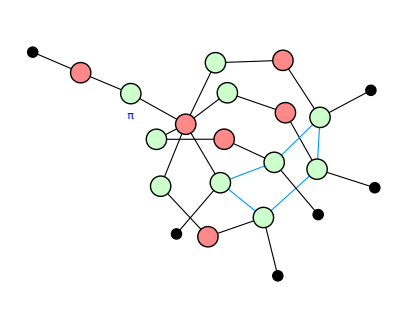

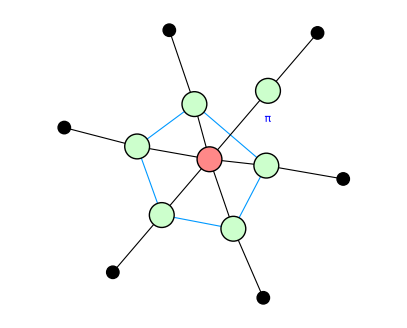

In [5]:
simple = code.encoder().clone()
zx.simplify.id_simp(simple)
zx.simplify.spider_simp(simple)
print("the same map:", zx.compare_tensors(code.encoder(), simple, preserve_scalar=False))
display(draw_relaxed(code.encoder(), figsize=(5, 4)))
draw_relaxed(simple, figsize=(5, 4))

Simplified, it is the textbook picture of the [[5,1,3]] code. The five qubits (green, each with its output wire) are joined in a ring of CZ gates (the blue Hadamard edges): the ring of the program's encoder. The input reaches all five through one red spider, which copies it in the X basis, $|+\rangle \mapsto |+\rangle^{\otimes 5}$ and $|-\rangle \mapsto |-\rangle^{\otimes 5}$, before the ring. So the code words are the ring states $\mathrm{CZ}_{\text{ring}}|+\rangle^{\otimes 5}$ and $\mathrm{CZ}_{\text{ring}}|-\rangle^{\otimes 5}$: the [[5,1,3]] code as a graph code on a ring of five.

The $\pi$ on the input (a $Z$ gate) fixes the signs. With it, $E X = \bar X E$ for $\bar X = +XXXXX$, as checked above; without it, $\bar X E = -E X$:

In [6]:
pi_spider = next(v for v in simple.vertices() if simple.phase(v) == 1)
no_pi = simple.clone()                              # clone keeps the vertex numbers
no_pi.set_phase(pi_spider, 0)
E0 = no_pi.to_matrix()
E0 = E0 / np.linalg.norm(E0[:, 0])
print("without the pi:  Xbar E = E X:", np.allclose(matrix(code.logical_x[0]) @ E0, E0 @ PAULI['X']),
      "   Xbar E = -E X:", np.allclose(matrix(code.logical_x[0]) @ E0, -E0 @ PAULI['X']))

without the pi:  Xbar E = E X: False    Xbar E = -E X: True


### The isometry AP normal form

Yeh, Huang, Kissinger, Li and van de Wetering write every Clifford isometry, such as an ideal encoder, in a normal form of three layers (the isometry affine-with-phases normal form, Figure 4.12 of the thesis), read from the inputs to the outputs:

* $U_I$, a Clifford on the logical inputs: $S$ and CZ gates, then Hadamards, then X-CZ gates (two red spiders joined by a Hadamard edge);
* the **core**, a phase-free CSS encoder in X-Z parity form: a red spider on each input and one for each Z-check, each with a phase $0$ or $\pi$, joined to a green spider on each output;
* $U_O$, a diagonal Clifford on the outputs: phases in multiples of $\pi/2$ and CZ gates.

`iap_normal_form` computes it (from a code, or from the diagram of any Clifford isometry), and `draw` shades the three layers. Their manuscript is not public yet, so the conventions that make the form unique are derived here; they are listed in the module `zxqec.codes.iapnf`, and the tests check, on thousands of ways of writing the same isometry, that the form does not depend on the way. For the [[5,1,3]] code:

isometry AP normal form: 1 input(s) -> 5 output(s)
  U_I   S on inputs none; CZ none; H on inputs none; X-CZ none
  core  input X-spiders: input 0 -> outputs {1, 2, 3, 4, 5}
        Z-check X-spiders: none
  U_O   phases 1: pi, 2: pi, 3: pi, 4: pi, 5: pi; CZ 1-2, 1-5, 2-3, 3-4, 4-5
the same map as the ideal encoder: True


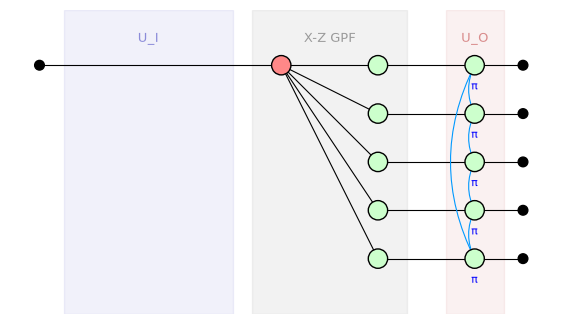

In [7]:
nf = iap_normal_form(code)
print(nf)
print("the same map as the ideal encoder:", zx.compare_tensors(nf.to_graph(), code.encoder(), preserve_scalar=False))
nf.draw()

Read from left to right. $U_I$ is empty: the logical qubit needs no Clifford before the core. The core copies the input in the X basis onto all five qubits (its one red spider is joined to all five green ones) and has no Z-checks. $U_O$ is the ring of CZ gates, with a $\pi$ on every qubit, which gives the logical $X$ its sign. It is the simplified picture above, now in the three layers of the normal form.

## 3. Blocks and what they do

Now a whole program: encode, measure the four checks, and apply `H` then `S` to every qubit of the code. The last block is given the role *transversal gate* (see `TransversalGates.ipynb`).

In [8]:
p = five_qubit_program([HAD, S], 'H then S on every qubit')
level = p.group_stages([(0, 0, 'encode', 'encoder'), (1, 1, 'checks', 'syndrome extraction'),
                        (2, 2, 'H then S on every qubit', 'transversal gate')])
s = p.summary(level)
print(s.table())
print()
print(s.blocks[2].describe())
print()
print("the same code after the gate as before:", s.blocks[2].code_in.same_code_as(s.blocks[2].code_out))

block                      role                 code before  code after  logical action  every run?  checks
0 encode                   encoder              [[1,1,1]]    [[5,1,3]]   I               yes         ok
1 checks                   syndrome extraction  [[5,1,3]]    [[5,1,3]]   I               yes         ok
2 H then S on every qubit  transversal gate     [[5,1,3]]    [[5,1,3]]   SH              yes         ok

Block 2 'H then S on every qubit' (transversal gate) -- stages 2
  code before: [[5,1,3]] on qubits 1,2,3,4,5
  code after:  [[5,1,3]] on qubits 1,2,3,4,5
  logical action: deterministic: every run implements SH
  ok      implements SH in every run
  ok      transversal: no two qubits of one code block are connected by its gates

the same code after the gate as before: True


The program, one shade per block: the encoder, the four checks (each measured with helper qubit 6, which is reset after each measurement), and $H$ then $S$ on every qubit of the code.

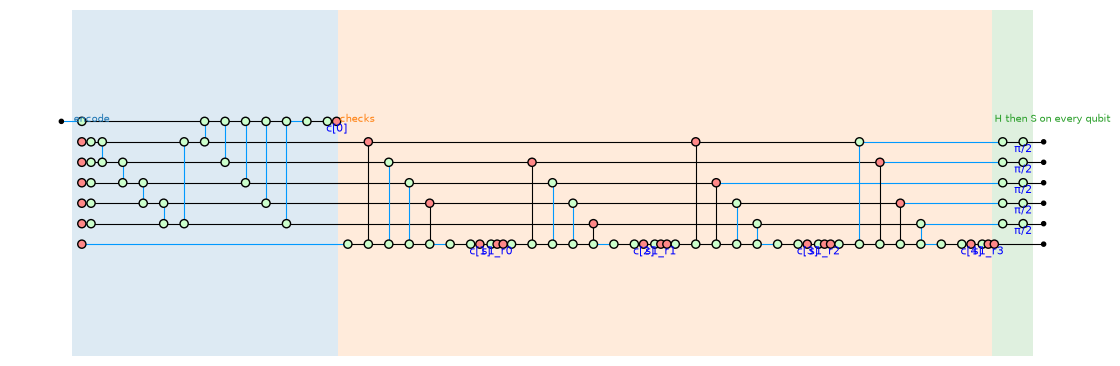

In [9]:
draw_program(p, level=level, show_time=False, figsize=(14, 4.5))

* The **encoder** puts the input into the code without changing it (`I`).
* The **round of checks** leaves the code and the logical state alone.
* `H` then `S` on every qubit **keeps the [[5,1,3]] code** and is the **logical `SH`**, in every run (`SH` is the operator: first `H`, then `S`). It is a Clifford gate of order three, which the [[5,1,3]] code is known to have transversally; here it is found from the gates.

The four check results are always 0, since the code was just prepared. `check_detectors` confirms it:

In [10]:
print(check_detectors(p, [['c[1]'], ['c[2]'], ['c[3]'], ['c[4]']]))

4 declared detector(s): 4 deterministic (value 0), 0 not deterministic, 0 unknown
the program has 4 independent detectors on its results, all sums of declared ones


### A gate on every qubit that does not keep the code

`H` on every qubit is transversal too, but it maps the [[5,1,3]] code to a *different* code (its stabilizers become `ZXXZI` and its shifts). Asked for the logical action from the [[5,1,3]] code back to the [[5,1,3]] code, the tool says the block leaves it:

In [11]:
q = five_qubit_program([HAD], 'H on every qubit')
level = q.group_stages([(0, 0, 'encode', 'encoder'), (1, 1, 'checks', 'syndrome extraction'),
                        (2, 2, 'H on every qubit', 'transversal gate')])
b = q.summary(level).blocks[2]
print("the same code after the gate as before:", b.code_in.same_code_as(b.code_out))
act = logical_action(q.block_graph(level, 2, classical=False), b.code_in, b.code_in)
print(act.verdict())

the same code after the gate as before: False
leaves the code: the block maps part of the code before it outside the code after it, so it is not a logical operation (between the ideal encoders it looks like H, but shrunk)


## 4. The Steane code after one S gate

An `S` gate on one qubit of the Steane code gives a code that is not CSS (on that qubit, `X` becomes `Y` in the stabilizers). `S^dag` on that qubit, then `H` on every qubit, then `S` on that qubit again, is a logical `H` of the new code:

In [12]:
p = QProgram(7, initial_states={q: '0' for q in range(7) if q != 3})
c = Circuit(7)
for gate in steane_encoder(list(range(7))):
    c.add_gate(gate)
p.add_circuit(c, name='encode')
c = Circuit(7)
c.add_gate(S(0))
p.add_circuit(c, name='S on qubit 0')
c = Circuit(7)
for _ in range(3):
    c.add_gate(S(0))                                # S^dag = S^3
for q in range(7):
    c.add_gate(HAD(q))
c.add_gate(S(0))
p.add_circuit(c, name='H in the new code')
print(p.code_at(1))
print()
print(p.summary(p.group_stages([(0, 0, 'encode', 'encoder'), (1, 1, 'S on qubit 0', 'logical gate'),
                                (2, 2, 'H in the new code', 'transversal gate')])).table())

[[7, 1, 3]] stabilizer code on qubits 0, 1, 2, 3, 4, 5, 6
    stabilizer +IXXXIXI
    stabilizer +IXIXXIX
    stabilizer +YXXIXII
    stabilizer +ZZZIZII
    stabilizer +ZZIIIZZ
    stabilizer +ZIZZIIZ
    logical X IXXIIIX   logical Z ZZIZIII

block                role              code before  code after  logical action  every run?  checks
0 encode             encoder           [[1,1,1]]    [[7,1,3]]   I               yes         ok
1 S on qubit 0       logical gate      [[7,1,3]]    [[7,1,3]]   I               yes         ok
2 H in the new code  transversal gate  [[7,1,3]]    [[7,1,3]]   H               yes         ok


The `S` gate is the logical identity from the Steane code into the new code, and the conjugated Hadamards are its logical `H`, in every run.

Both codes in the isometry AP normal form. They share the core, the Steane code itself (the input joined to qubits 3, 5, 6, and its three Z-checks), and the $S$ shows up only in $U_O$. But not on qubit 0: $U_O$ acts only on the qubits the Z-checks leave free (3, 4, 5, 6; qubits 0, 1, 2 are the pivots of the checks), and on the code the value of qubit 0 is $z_3 \oplus z_4 \oplus z_5$ (the first Z-check). So $S$ on qubit 0, the phase $i^{z_0}$, is $i^{z_3 + z_4 + z_5} (-1)^{z_3 z_4 + z_3 z_5 + z_4 z_5}$: $S$ on qubits 3, 4, 5 and a CZ between each pair. Writing every phase on the free qubits is what makes the form unique.

the Steane code
isometry AP normal form: 1 input(s) -> 7 output(s)
  U_I   S on inputs none; CZ none; H on inputs none; X-CZ none
  core  input X-spiders: input 0 -> outputs {3, 5, 6}
        Z-check X-spiders: outputs {0, 3, 4, 5}, outputs {1, 3, 4, 6}, outputs {2, 4, 5, 6}
  U_O   phases none; CZ none
  the same map as the ideal encoder: True

after S on qubit 0
isometry AP normal form: 1 input(s) -> 7 output(s)
  U_I   S on inputs none; CZ none; H on inputs none; X-CZ none
  core  input X-spiders: input 0 -> outputs {3, 5, 6}
        Z-check X-spiders: outputs {0, 3, 4, 5}, outputs {1, 3, 4, 6}, outputs {2, 4, 5, 6}
  U_O   phases 3: pi/2, 4: pi/2, 5: pi/2; CZ 3-4, 3-5, 4-5
  the same map as the ideal encoder: True



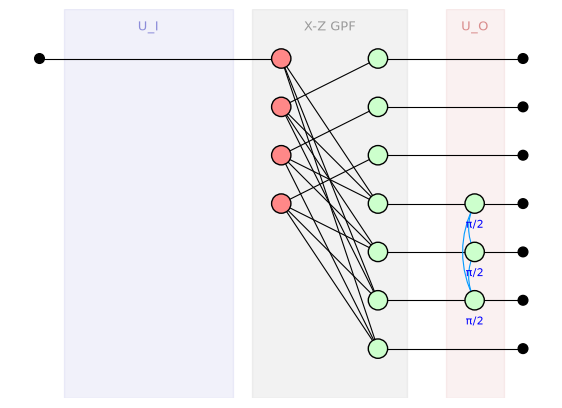

In [13]:
for name, c in (("the Steane code", p.code_at(0)), ("after S on qubit 0", p.code_at(1))):
    print(name)
    print(iap_normal_form(c))
    print("  the same map as the ideal encoder:",
          zx.compare_tensors(iap_normal_form(c).to_graph(), c.encoder(), preserve_scalar=False))
    print()
iap_normal_form(p.code_at(1)).draw()

## What is not covered

When a Clifford gate is applied only in *some* runs (here `S` on qubit 0 when a random bit `m` is 1), the code itself differs between runs. The tool cannot read such a code, and says so in the block's row instead of guessing:

In [14]:
p = QProgram(8, bits=1, initial_states={**{q: '0' for q in range(7) if q != 3}, 7: '+'})
c = Circuit(8, bit_amount=1)
for gate in steane_encoder(list(range(7))):
    c.add_gate(gate)
c.add_gate(Measurement(7, result_symbol='m'))
p.add_circuit(c, name='encode, and a random bit m')
c = Circuit(8, bit_amount=1)
c.add_gate(ParityControlled('S', 0, ['m']))
p.add_circuit(c, name='S if m = 1')
s = p.summary(0)
print(s.table())
print()
print([msg for ok, msg in s.blocks[1].checks if not ok][0])

block                         role  code before  code after  logical action  every run?  checks
0 encode, and a random bit m  -     [[1,1,1]]    [[7,1,3]]   I               yes         ok
1 S if m = 1                  -     [[7,1,3]]    ?           ?               ?           1 problem(s)

the code after the block could not be identified: a Clifford phase controlled by measurement outcomes gives the X stabilizer on qubits 0, 1, 2, 4 a Z part (or a factor i) in some runs only, so the code differs between runs; reading it run by run is not implemented


The same checks are in the test suite (`tests/test_noncss.py`), which also compares the ideal encoder of 27 codes that are not CSS with its definition, and the logical action of 49 stages of random programs with `B E_in = E_out L`.